Emilio Alejandro González Huerta A01286440

---

# Optimización con PSO y Colonia de Abejas Artificiales (ABC)

Se busca el máximo de dos funciones:

**Función 1**, en $x \in [-5,5],\; y \in [-5,5]$

$$f_1(x,y) = \frac{-3y}{x^2 + y^2 + 1}$$

**Función 2**, en $x \in [-3,3],\; y \in [-3,3]$

$$f_2(x,y) = 3(1-x)^2 e^{-x^2-(y+1)^2} - 10\,e^{-x^2-y^2}\left(-x^3 + \frac{x}{5} - y^5\right) - \frac{1}{3}e^{-(x+1)^2-y^2}$$

---

> ### **Inicialización**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

In [2]:
def f1(x, y):
    return -(3 * y) / (x**2 + y**2 + 1)

def f2(x, y):
    return (3 * (1 - x)**2 * np.exp(-x**2 - (y + 1)**2)
            - 10 * np.exp(-x**2 - y**2) * (-x**3 + x / 5 - y**5)
            - (1 / 3) * np.exp(-(x + 1)**2 - y**2))

# Diccionario con función, lower bound, upper bound
problemas = {
    'f1': {'func': f1, 
           'lb': np.array([-5.0, -5.0]), 
           'ub': np.array([5.0, 5.0])},
    'f2': {'func': f2, 
           'lb': np.array([-3.0, -3.0]), 
           'ub': np.array([3.0, 3.0])},
}

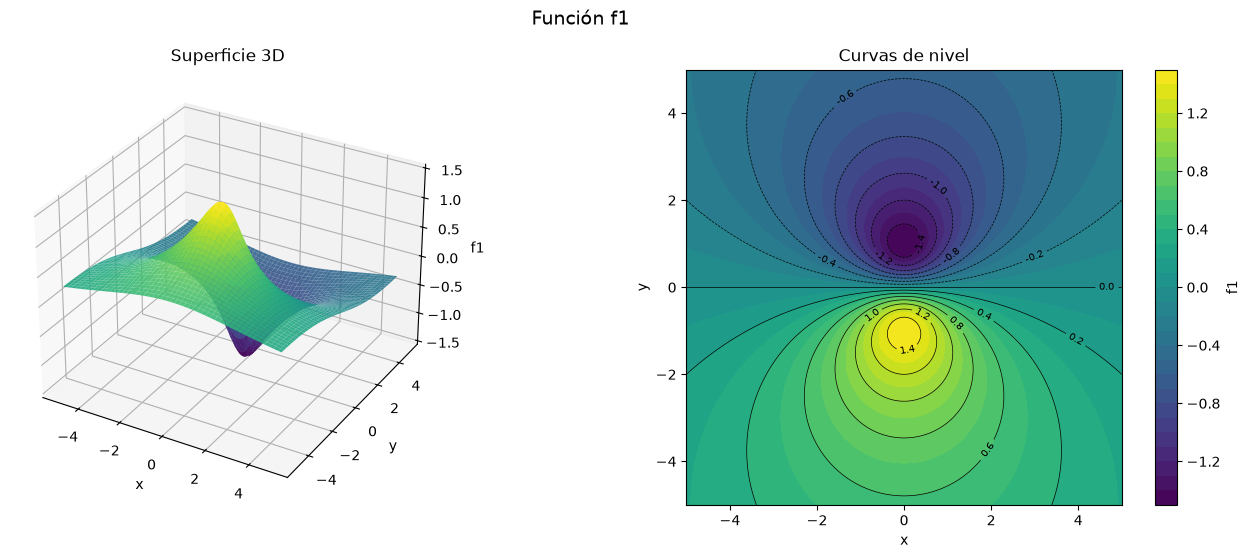

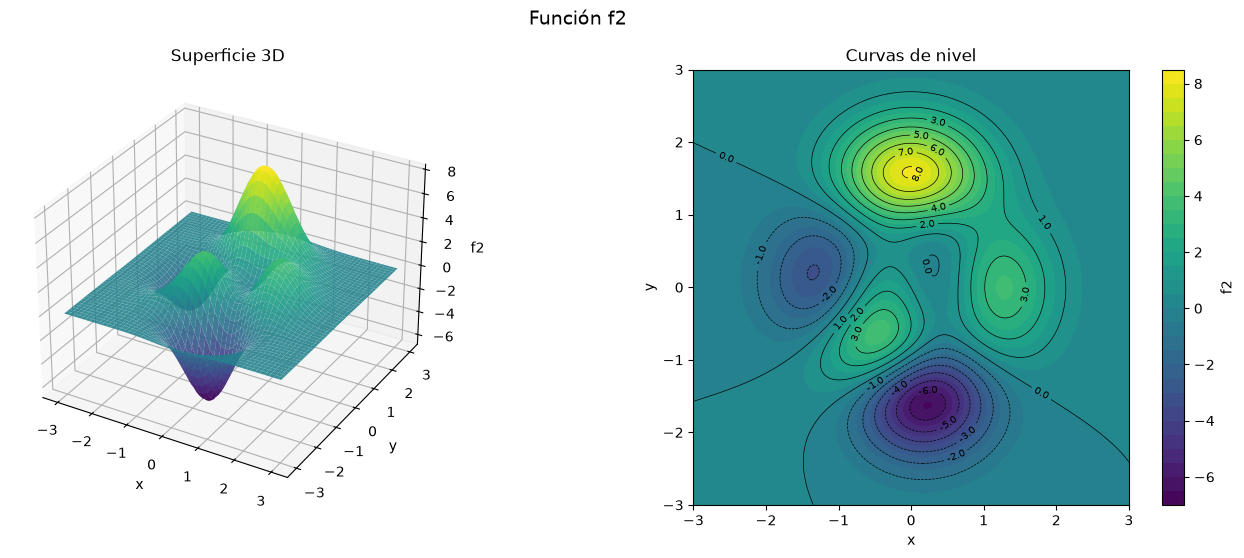

In [ ]:
for nombre, p in problemas.items():
    xs = np.linspace(p['lb'][0], p['ub'][0], 200)
    ys = np.linspace(p['lb'][1], p['ub'][1], 200)
    X, Y = np.meshgrid(xs, ys)
    Z = p['func'](X, Y)

    fig = plt.figure(figsize=(14, 5.5))
    fig.suptitle(f'Función {nombre}', fontsize=14)

    ax1 = fig.add_subplot(1, 2, 1, projection='3d')
    ax1.plot_surface(X, Y, Z, cmap='viridis', alpha=0.9, linewidth=0)
    ax1.set_title('Superficie 3D')
    ax1.set_xlabel('x'); 
    ax1.set_ylabel('y'); 
    ax1.set_zlabel(nombre)

    ax2 = fig.add_subplot(1, 2, 2)
    relleno = ax2.contourf(X, Y, Z, levels=30, cmap='viridis')            
    lineas = ax2.contour(X, Y, Z, levels=15, colors='black', linewidths=0.5) 
    ax2.clabel(lineas, inline=True, fontsize=7, fmt='%.1f')               
    fig.colorbar(relleno, ax=ax2, label=nombre)
    ax2.set_title('Curvas de nivel')
    ax2.set_xlabel('x'); 
    ax2.set_ylabel('y')
    ax2.set_aspect('equal')

    plt.tight_layout(); plt.show()

---

> ### **PSO**

Cada partícula $i$ tiene posición $x_i$ y velocidad $v_i$, donde:

$$v_i \leftarrow w\,v_i + c_1 r_1 (p_i - x_i) + c_2 r_2 (g - x_i)$$
$$x_i \leftarrow x_i + v_i$$

- $p_i$ es la mejor posición propia
- $g$ la mejor global 
- $r_1, r_2$ son números aleatorios distribuidos de la forma $U(0,1)$. 

Nota:
- La velocidad se limita a $[-v_{max}, v_{max}]$ y la posición $x$ a los límites del dominio.

### Parámetros utilizados

| Parámetro | Valor | Justificación |
|---|---|---|
| Tamaño de población | 30 partículas | Valor estándar para problemas de 2 dimensiones |
| Iteraciones | 100 | Presupuesto de 3,000 evaluaciones (igual que ABC) |
| $w$ (inercia) | 0.729 | Coeficiente de constricción de Clerc–Kennedy |
| $c_1$ (cognitivo) | 1.49445 | Clerc–Kennedy, garantiza convergencia |
| $c_2$ (social) | 1.49445 | Clerc–Kennedy, garantiza convergencia |
| $v_{max}$ | 20 % del rango de cada variable → **2.0** en $f_1$, **1.2** en $f_2$ | Evita que las partículas salten fuera del dominio |
| Velocidad inicial | Aleatoria uniforme en $[-v_{max}, v_{max}]$ | Diversidad inicial del enjambre |

In [ ]:
PSO_PARAMS = {
    'n_particulas': 30,
    'iteraciones': 100,
    'w': 0.729,
    'c1': 1.49445,
    'c2': 1.49445,
    'factor_vmax': 0.20,   # 20% del rango de cada problema
}

In [26]:
def pso(func, lb, ub, n_particulas, iteraciones, w, c1, c2, factor_vmax, SEED=42):
    rng = np.random.default_rng(SEED)
    vmax = factor_vmax * (ub - lb)

    # Parte inicial, todo en matrices
    # Las particulas de un PSO no se afectan hasta que se acaba toda la iteración
    x = rng.uniform(lb, ub, (n_particulas, 2))
    v = rng.uniform(-vmax, vmax, (n_particulas, 2))
    v_inicial = v.copy()

    fit = func(x[:, 0], x[:, 1])
    pbest, pbest_fit = x.copy(), fit.copy()
    g = np.argmax(pbest_fit)
    gbest, gbest_fit = pbest[g].copy(), pbest_fit[g]
    historia = [gbest_fit]

    # Parte interativa
    for _ in range(iteraciones):
        r1 = rng.random((n_particulas, 2))
        r2 = rng.random((n_particulas, 2))
        v = w*v + c1*r1*(pbest - x) + c2*r2*(gbest - x) 
        v = np.clip(v, -vmax, vmax)                  
        x = np.clip(x + v, lb, ub)                  

        fit = func(x[:, 0], x[:, 1])
        mejora = fit > pbest_fit # este coso maximiza
        pbest[mejora], pbest_fit[mejora] = x[mejora], fit[mejora]
        g = np.argmax(pbest_fit)
        if pbest_fit[g] > gbest_fit:
            gbest, gbest_fit = pbest[g].copy(), pbest_fit[g]
        historia.append(gbest_fit)

    return {'mejor_pos': gbest, 'mejor_val': gbest_fit, 'historia': np.array(historia),
            'vmax': vmax, 'v_inicial': v_inicial,
            'evaluaciones': n_particulas * (iteraciones + 1)}

---

> ### **ABC**

Se tienen tres tipos de abejas que trabajan sobre $SN$ fuentes de alimento:

1. **Abejas empleadas**: cada una explora un vecino de su fuente, $v_{ij} = x_{ij} + \phi_{ij}(x_{ij} - x_{kj})$ con $\phi \sim U(-1,1)$ y $k \neq i$ aleatorio. De forma greedy se queda con la mejor.
2. **Abejas observadoras**: eligen fuentes con probabilidad proporcional a su aptitud y las explotan igual que las empleadas.
3. **Abejas exploradoras**: una fuente que no mejora después de un número de intentos se abandona y se reemplaza por una aleatoria.

Como se busca un máximo, la aptitud será $fit_i = f_i - \min(f) + \varepsilon$ (siempre positiva).

### Parámetros utilizados

| Parámetro | Valor |
|---|---|
| Tamaño de la colonia | 30 abejas (15 empleadas + 15 observadoras) |
| Fuentes de alimento $SN$ | 15 |
| `limite` de abandono | $SN \times D = 15 \times 2 = 30$ |
| Iteraciones | 100 (≈ 3,000 evaluaciones, igual que PSO) |

In [12]:
ABC_PARAMS = {
    'n_abejas': 30,    # empleadas + observadoras
    'iteraciones': 100,
    'limite': None,       # None -> SN * D
}

In [27]:
def abc(func, lb, ub, n_abejas, iteraciones, limite=None, SEED=42):
    rng = np.random.default_rng(SEED)
    SN = n_abejas // 2                      # número de fuentes = observadoras
    limite = SN * 2 if limite is None else limite

    fuentes = rng.uniform(lb, ub, (SN, 2))
    valores = func(fuentes[:, 0], fuentes[:, 1])
    intentos = np.zeros(SN, dtype=int)
    evals = SN

    b = np.argmax(valores)
    mejor_pos, mejor_val = fuentes[b].copy(), valores[b]
    historia = [mejor_val]

    def explorar_vecino(i):
        nonlocal evals
        k = rng.choice([j for j in range(SN) if j != i])
        d = rng.integers(2)
        nueva = fuentes[i].copy()
        nueva[d] += rng.uniform(-1, 1) * (fuentes[i, d] - fuentes[k, d])
        nueva = np.clip(nueva, lb, ub)
        val = func(nueva[0], nueva[1]); evals += 1
        if val > valores[i]:                     # selección voraz (maximización)
            fuentes[i], valores[i], intentos[i] = nueva, val, 0
        else:
            intentos[i] += 1

    for _ in range(iteraciones):
        # Fase de abejas empleadas
        for i in range(SN):
            explorar_vecino(i)

        # Fase de abejas observadoras (selección por ruleta)
        aptitud = valores - valores.min() + 1e-12
        prob = aptitud / aptitud.sum()
        for _ in range(SN):
            explorar_vecino(rng.choice(SN, p=prob))

        # Guardar la mejor solución encontrada
        b = np.argmax(valores)
        if valores[b] > mejor_val:
            mejor_pos, mejor_val = fuentes[b].copy(), valores[b]

        # Fase de abejas exploradoras
        agotada = np.argmax(intentos)
        if intentos[agotada] > limite:
            fuentes[agotada] = rng.uniform(lb, ub)
            valores[agotada] = func(fuentes[agotada, 0], fuentes[agotada, 1]); evals += 1
            intentos[agotada] = 0

        historia.append(mejor_val)

    return {'mejor_pos': mejor_pos, 'mejor_val': mejor_val, 'historia': np.array(historia),
            'SN': SN, 'limite': limite, 'evaluaciones': evals}

> ### **Óptimo**

In [21]:
from scipy.optimize import minimize

referencia = {}
for nombre, p in problemas.items():
    X, Y = np.meshgrid(np.linspace(p['lb'][0], p['ub'][0], 501), np.linspace(p['lb'][1], p['ub'][1], 501))
    Z = p['func'](X, Y)
    i = np.unravel_index(Z.argmax(), Z.shape)
    r = minimize(lambda q: -p['func'](*q), [X[i], Y[i]], bounds=list(zip(p['lb'], p['ub'])))
    referencia[nombre] = -r.fun
    print(f"{nombre}: máximo = {-r.fun:.6f} en (x, y) = ({r.x[0]:.4f}, {r.x[1]:.4f})")

f1: máximo = 1.500000 en (x, y) = (0.0000, -1.0000)
f2: máximo = 8.106214 en (x, y) = (-0.0093, 1.5814)


---

> ### **Resultados**

In [22]:
resultados_individuales = {}
for nombre, p in problemas.items():
    print(f"=================== {nombre} ===================")

    t0 = time.perf_counter()
    r_pso = pso(p['func'], p['lb'], p['ub'], **PSO_PARAMS)
    t_pso = time.perf_counter() - t0
    print("PSO")

    print(f"  Máximo encontrado: f = {r_pso['mejor_val']:.6f} en (x, y) = {r_pso['mejor_pos']}")
    print(f"  Tiempo: {t_pso*1000:.2f} ms | Evaluaciones: {r_pso['evaluaciones']}")

    t0 = time.perf_counter()
    r_abc = abc(p['func'], p['lb'], p['ub'], **ABC_PARAMS)
    t_abc = time.perf_counter() - t0
    print("ABC")
    
    print(f"  Máximo encontrado: f = {r_abc['mejor_val']:.6f} en (x, y) = {r_abc['mejor_pos']}")
    print(f"  Tiempo: {t_abc*1000:.2f} ms | Evaluaciones: {r_abc['evaluaciones']}")
    print(f"Referencia (malla): {referencia[nombre]:.6f}\n")

    resultados_individuales[nombre] = {'PSO': r_pso, 'ABC': r_abc}

=================== f1 ===================
PSO
  Máximo encontrado: f = 1.500000 en (x, y) = [-2.36859856e-07 -9.99998573e-01]
  Tiempo: 4.29 ms | Evaluaciones: 3030
ABC
  Máximo encontrado: f = 1.500000 en (x, y) = [-6.76782044e-09 -9.99999994e-01]
  Tiempo: 82.88 ms | Evaluaciones: 3026
Referencia (malla): 1.500000

=================== f2 ===================
PSO
  Máximo encontrado: f = 8.106214 en (x, y) = [-0.0093162   1.58136856]
  Tiempo: 4.94 ms | Evaluaciones: 3030
ABC
  Máximo encontrado: f = 8.106213 en (x, y) = [-0.00934074  1.58147061]
  Tiempo: 83.81 ms | Evaluaciones: 3021
Referencia (malla): 8.106214



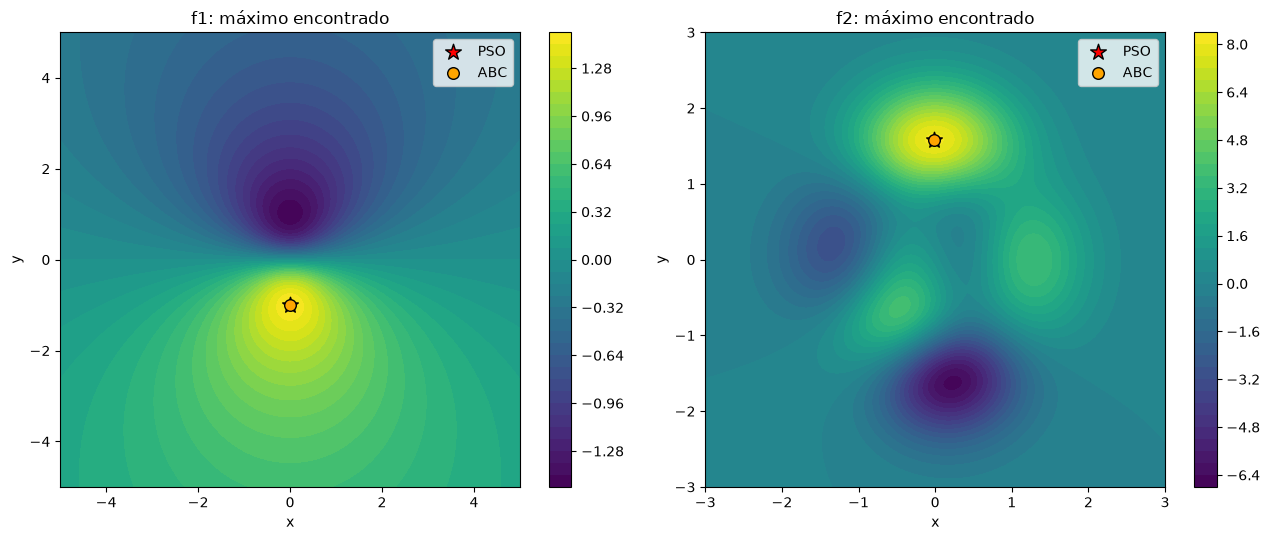

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, (nombre, p) in zip(axes, problemas.items()):
    xs = np.linspace(p['lb'][0], p['ub'][0], 300)
    ys = np.linspace(p['lb'][1], p['ub'][1], 300)
    X, Y = np.meshgrid(xs, ys)
    cs = ax.contourf(X, Y, p['func'](X, Y), levels=40, cmap='viridis')
    fig.colorbar(cs, ax=ax)
    r = resultados_individuales[nombre]
    ax.scatter(*r['PSO']['mejor_pos'], c='red', s=140, marker='*', edgecolor='k', label='PSO')
    ax.scatter(*r['ABC']['mejor_pos'], c='orange', s=70, marker='o', edgecolor='k', label='ABC')
    ax.set_title(f'{nombre}: máximo encontrado'); ax.set_xlabel('x'); ax.set_ylabel('y')
    ax.legend()
plt.tight_layout(); plt.show()

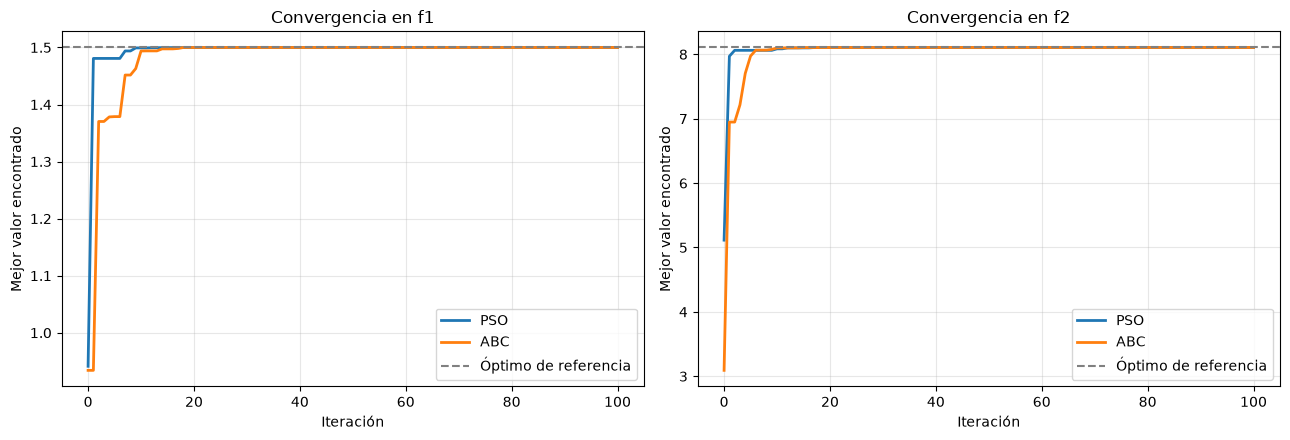

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, nombre in zip(axes, problemas):
    r = resultados_individuales[nombre]
    ax.plot(r['PSO']['historia'], label='PSO', lw=2)
    ax.plot(r['ABC']['historia'], label='ABC', lw=2)
    ax.axhline(referencia[nombre], color='gray', ls='--', label='Óptimo de referencia')
    ax.set_title(f'Convergencia en {nombre}')
    ax.set_xlabel('Iteración'); ax.set_ylabel('Mejor valor encontrado')
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

> ### **Comparación estadística**

Se repite cada experimento 30 veces con semillas distintas y se mide:

In [ ]:
N_CORRIDAS = 30
TOL = 1e-4

def iter_convergencia(historia, optimo, tol=TOL):
    idx = np.where(np.abs(optimo - historia) < tol)[0]
    return idx[0] if len(idx) else np.nan

registros, historias = [], {}
for nombre, p in problemas.items():
    for alg, fn, params in [('PSO', pso, PSO_PARAMS), ('ABC', abc, ABC_PARAMS)]:
        hs = []
        for s in range(N_CORRIDAS):
            t0 = time.perf_counter()
            r = fn(p['func'], p['lb'], p['ub'], **params, SEED=s)
            t = time.perf_counter() - t0
            hs.append(r['historia'])
            registros.append({'Función': nombre, 'Algoritmo': alg, 'Semilla': s,
                              'Máximo': r['mejor_val'], 'x': r['mejor_pos'][0], 'y': r['mejor_pos'][1],
                              'Error': abs(referencia[nombre] - r['mejor_val']),
                              'Iter_conv': iter_convergencia(r['historia'], referencia[nombre]),
                              'Tiempo_ms': t * 1000, 'Evaluaciones': r['evaluaciones']})
        historias[(nombre, alg)] = np.array(hs)

df = pd.DataFrame(registros)

resumen = df.groupby(['Función', 'Algoritmo']).agg(
    Mejor=('Máximo', 'max'),
    Promedio=('Máximo', 'mean'),
    Peor=('Máximo', 'min'),
    Desv_Est=('Máximo', 'std'),
    Error_prom=('Error', 'mean'),
    Tiempo_ms_prom=('Tiempo_ms', 'mean'),
    Tiempo_ms_desv=('Tiempo_ms', 'std'),
    Exito_pct=('Error', lambda e: 100 * np.mean(e < TOL))
)
pd.set_option('display.float_format', lambda v: f'{v:.6g}')
resumen

Mejor  Promedio    Peor    Desv_Est  Error_prom  \
Función Algoritmo                                                     
f1      ABC           1.5       1.5     1.5           0 2.22045e-16   
        PSO           1.5       1.5     1.5 5.48056e-12 3.16545e-12   
f2      ABC       8.10621   8.10621 8.10612 2.33414e-05 7.55558e-06   
        PSO       8.10621   7.81144 3.59249     1.12208    0.294779   

                   Tiempo_ms_prom  Tiempo_ms_desv  Exito_pct  
Función Algoritmo                                             
f1      ABC               83.4824         6.36853        100  
        PSO               3.74533         1.71532        100  
f2      ABC               89.2267         8.59488        100  
        PSO               4.98415        0.206057    93.3333

In [32]:
fallos_pso = df[(df['Algoritmo'] == 'PSO') & (df['Error'] >= TOL)]
fallos_pso[['Función', 'Semilla', 'Máximo', 'x', 'y', 'Error']]

,Función,Semilla,Máximo,x,y,Error
76,f2,16,3.59249,1.28568,-0.00484763,4.51372
80,f2,20,3.77658,-0.460025,-0.629197,4.32963
